# figure 3
light environment and modelled gpp response for smoke and stratospheric sulfate (results from 2_smoke_regression)

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
import matplotlib.patheffects as pe

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 7, "axes.labelsize": 7, "xtick.labelsize": 6, "ytick.labelsize": 6,
    "legend.fontsize": 6, "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "pdf.fonttype": 42, "axes.titlelocation": "left"})
mm = 1 / 25.4
minus = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}".replace("-", "−"))
Path("figures").mkdir(exist_ok=True)
light = pd.read_csv("results/light_curves.csv")
points = pd.read_csv("results/smoke_light_points.csv")
curves = pd.read_csv("results/radiation_curves.csv")
observed = pd.read_csv("results/observed_radiation.csv")
pin = pd.read_csv("results/pinatubo.csv", dtype={"year": str})
orange, blue, darkblue, darkgreen = "#c47900", "#70a0cd", "#003466", "#004f00"
style = {"smoke": (orange, "Smoke (libRadtran)"), "sulfate": (blue, "Sulfate, r$_{eff}$ = 0.4 µm (libRadtran)")}
offset = {"US-Ne1": (-8, 10, "right"), "US-Ne2": (10, 13, "left"), "US-Ne3": (8, -3, "left"), "US-Bi2": (-8, -9, "right"),
          "US-MMS": (-8, -6, "right"), "US-UMB": (8, -8, "left"), "US-Ha1": (10, 10, "left"), "US-xUN": (-8, 13, "right")}

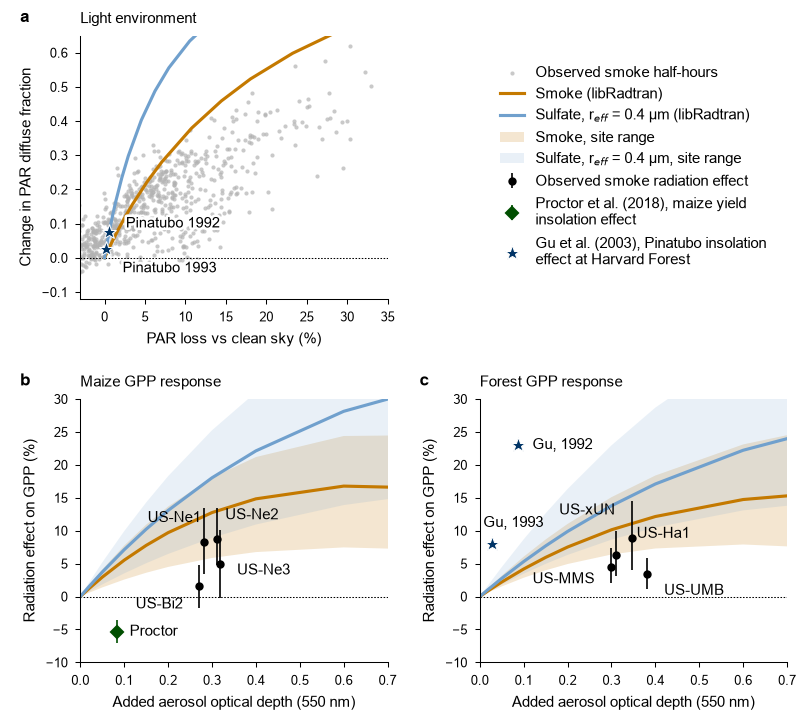

In [2]:
fig, ax4 = plt.subplots(2, 2, figsize=(136 * mm, 122 * mm))
axes = [ax4[0, 0], ax4[1, 0], ax4[1, 1]]
white = [pe.withStroke(linewidth=2.5, foreground="white")]

ax = axes[0]
ax.scatter(points.par_loss, points.dDF, s=4, color="#b2b2b2", alpha=0.7, lw=0, label="Observed smoke half-hours")
for case, (col, lab) in style.items():
    s = light[light.case == case]
    ax.plot(s.par_loss, s.dDF, color=col, label=lab)
for _, p in pin.iterrows():
    ax.plot(p.par_loss, p.dDF, marker="*", ms=7.5, color=darkblue, mec="white", mew=0.5, ls="none", zorder=5)
    ax.annotate(f"Pinatubo {p.year}", (p.par_loss, p.dDF), xytext=(8, -9 if p.year == "1993" else 4),
                textcoords="offset points", va="center", path_effects=white)
ax.axhline(0, color="black", lw=0.5, ls=(0, (1.5, 1.5)), zorder=1)
ax.set_xlim(-3, 35); ax.set_ylim(-0.12, 0.65)
ax.set_xlabel("PAR loss vs clean sky (%)"); ax.set_ylabel("Change in PAR diffuse fraction")
ax.set_title("Light environment")

for ax, g in ((axes[1], "maize"), (axes[2], "forest")):
    c = curves[curves.group == g].groupby(["case", "x"]).gpp.agg(["mean", "min", "max"]).reset_index()
    for case, (col, lab) in style.items():
        s = c[c.case == case]
        ax.plot(s.x, s["mean"], color=col, label=lab)
        ax.fill_between(s.x, s["min"], s["max"], color=col, alpha=0.18 if case == "smoke" else 0.15, lw=0,
                        label=f"{lab.split(' (')[0]}, site range")
    o = observed[observed.group == g]
    ax.errorbar(o.daod, o.pct, yerr=[o.pct - o.lo, o.hi - o.pct], fmt="o", ms=3, color="black", lw=0.8,
                label="Observed smoke radiation effect")
    for _, r in o.iterrows():
        dx, dy, ha = offset[r.site]
        ax.annotate(r.site, (r.daod, r.pct), xytext=(dx, dy), textcoords="offset points", ha=ha, va="center")
    if g == "maize":
        # proctor et al. 2018 fig 4e maize insolation effect, log points converted to percent
        pm, plo, phi = (100 * (np.exp(v / 100) - 1) for v in (-5.5, -7.3, -3.6))
        ax.errorbar([0.084], [pm], yerr=[[pm - plo], [phi - pm]], fmt="D", ms=3.75, color=darkgreen, lw=0.8, zorder=5,
                    label="Proctor et al. (2018), maize yield\ninsolation effect")
        ax.annotate("Proctor", (0.084, pm), xytext=(6, 0), textcoords="offset points", va="center")
    else:
        for _, p in pin.iterrows():
            ax.plot(p.aod, p.gpp, marker="*", ms=7.5, color=darkblue, mec="white", mew=0.5, ls="none", zorder=5,
                    label="Gu et al. (2003), Pinatubo insolation\neffect at Harvard Forest" if p.year == "1992" else None)
            ax.annotate(f"Gu, {p.year}", (p.aod, p.gpp), xytext=(7, 0) if p.year == "1992" else (-4, 10),
                        textcoords="offset points", va="center")
    ax.axhline(0, color="black", lw=0.5, ls=(0, (1.5, 1.5)), zorder=1)
    ax.set_xlim(0, 0.7); ax.set_ylim(-10, 30)
    ax.set_xlabel("Added aerosol optical depth (550 nm)"); ax.set_ylabel("Radiation effect on GPP (%)")
    ax.set_title(f"{g.capitalize()} GPP response")

fig.subplots_adjust(left=0.1, right=0.98, top=0.95, bottom=0.08, wspace=0.3, hspace=0.38)
for a, letter in zip(axes, "abc"):
    b = a.get_position()
    fig.text(b.x0 - 0.075, b.y1 + 0.014, letter, fontsize=8, fontweight="bold", va="bottom")
handles = {}
for a in axes:
    for h, l in zip(*a.get_legend_handles_labels()):
        handles.setdefault(l, h)
ax4[0, 1].axis("off")
ax4[0, 1].legend(list(handles.values()), list(handles), loc="center", borderaxespad=0, fontsize=7, handlelength=1.6)
fig.savefig("figures/fig3_smoke_vs_sulfate.png", dpi=600)